In [1]:
pip install pandas scikit-learn shap matplotlib numpy

Defaulting to user installation because normal site-packages is not writeable
  Using cached shap-0.54.1-cp312-abi3-win_amd64.whl.metadata (23 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
Using cached shap-0.54.1-cp312-abi3-win_amd64.whl (751 kB)
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.


An explainable patient triage system that:

- Looks at ICU patient vital signs
- Flags unusual/high-risk patients (anomaly detection)
- Explains WHY each patient was flagged (SHAP)
- Tests whether those explanations stay reliable when data shifts (concept drift)

I will try to cover these phases in my implementation.

- Section 1 Data Loading & Verification ← you are here
-  Section 2  Data Preparation
-   Section 3 Anomaly Detectio
-   Section 4 — SHAP Explanations
-   Section 5 — Concept Drift Smulation
-   Section 6 — Findings & Discussion



# SECTION 1
#### Data Loading

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
import shap

print("All libraries loaded successfully")

All libraries loaded successfully


In [6]:
charts_df=pd.read_csv(r"C:\Users\mt260005\Downloads\mimic-iii-clinical-database-demo-1.4\CHARTEVENTS.csv")
stays_df=pd.read_csv(r"C:\Users\mt260005\Downloads\mimic-iii-clinical-database-demo-1.4\ICUSTAYS.csv")

C:\Users\mt260005\AppData\Local\Temp\ipykernel_33392\644907371.py:1: DtypeWarning: Columns (8,10,13,14) have mixed types. Specify dtype option on import or set low_memory=False.
  charts_df=pd.read_csv(r"C:\Users\mt260005\Downloads\mimic-iii-clinical-database-demo-1.4\CHARTEVENTS.csv")


In [12]:
charts_df.shape

(758355, 15)

In [13]:
charts_df.columns

Index(['row_id', 'subject_id', 'hadm_id', 'icustay_id', 'itemid', 'charttime',
       'storetime', 'cgid', 'value', 'valuenum', 'valueuom', 'warning',
       'error', 'resultstatus', 'stopped'],
      dtype='object')

In [8]:
charts_df.head(5)

,row_id,subject_id,hadm_id,icustay_id,itemid,charttime,storetime,cgid,value,valuenum,valueuom,warning,error,resultstatus,stopped
0,5279021,40124,126179,279554.0,223761,2130-02-04 04:00:00,2130-02-04 04:35:00,19085,95.9,95.9,?F,0.0,0.0,NaN,NaN
1,5279022,40124,126179,279554.0,224695,2130-02-04 04:25:00,2130-02-04 05:55:00,18999,2222221.7,2222221.7,cmH2O,0.0,0.0,NaN,NaN
2,5279023,40124,126179,279554.0,220210,2130-02-04 04:30:00,2130-02-04 04:43:00,21452,15.0,15.0,insp/min,0.0,0.0,NaN,NaN
3,5279024,40124,126179,279554.0,220045,2130-02-04 04:32:00,2130-02-04 04:43:00,21452,94.0,94.0,bpm,0.0,0.0,NaN,NaN
4,5279025,40124,126179,279554.0,220179,2130-02-04 04:32:00,2130-02-04 04:43:00,21452,163.0,163.0,mmHg,0.0,0.0,NaN,NaN


In [9]:
stays_df.head(5)

,row_id,subject_id,hadm_id,icustay_id,dbsource,first_careunit,last_careunit,first_wardid,last_wardid,intime,outtime,los
0,12742,10006,142345,206504,carevue,MICU,MICU,52,52,2164-10-23 21:10:15,2164-10-25 12:21:07,1.6325
1,12747,10011,105331,232110,carevue,MICU,MICU,15,15,2126-08-14 22:34:00,2126-08-28 18:59:00,13.8507
2,12749,10013,165520,264446,carevue,MICU,MICU,15,15,2125-10-04 23:38:00,2125-10-07 15:13:52,2.6499
3,12754,10017,199207,204881,carevue,CCU,CCU,7,7,2149-05-29 18:52:29,2149-05-31 22:19:17,2.1436
4,12755,10019,177759,228977,carevue,MICU,MICU,15,15,2163-05-14 20:43:56,2163-05-16 03:47:04,1.2938


What both tells us: 
charts_df is also linked to stays_df (icustay_id) and admission.csv (hadm_id ) . So, futher detail of stay can be drilled down to stays_df

# SECTION 2
#### Data Preparation 

- Since we need to work on vitals so, we need to load the file here and extract the 5 main vitals that we are going to work on.
- Every vital has a unique item number that maps it to human readable name. among all others, using those itemid we are going to extract those 5 labels.

In [20]:
vitals_df= pd.read_csv(r"C:\Users\mt260005\Downloads\mimic-iii-clinical-database-demo-1.4\D_ITEMS.csv")
vitals_df.head(5)


,row_id,itemid,label,abbreviation,dbsource,linksto,category,unitname,param_type,conceptid
0,1,1435,Sustained Nystamus,NaN,carevue,chartevents,NaN,NaN,NaN,NaN
1,2,1436,Tactile Disturbances,NaN,carevue,chartevents,NaN,NaN,NaN,NaN
2,3,1437,Tremor,NaN,carevue,chartevents,NaN,NaN,NaN,NaN
3,4,1438,Ulnar Pulse [Right],NaN,carevue,chartevents,NaN,NaN,NaN,NaN
4,5,1439,Visual Disturbances,NaN,carevue,chartevents,NaN,NaN,NaN,NaN


- These are the vitals that we are most concerned with atm

In [23]:
print(vitals_df[vitals_df['itemid'].isin([220045, 220179, 220180, 223761, 220210])][['itemid', 'label']])

      itemid                                  label
9524  220045                             Heart Rate
9546  220179   Non Invasive Blood Pressure systolic
9547  220180  Non Invasive Blood Pressure diastolic
9550  220210                       Respiratory Rate
9569  223761                 Temperature Fahrenheit


In [11]:
# MIMIC-III item IDs for our 5 vital signs
vital_ids = {
    220045: 'heart_rate',
    220179: 'systolic_bp',
    220180: 'diastolic_bp',
    223761: 'temperature',
    220210: 'respiratory_rate'
}

# flter only the rows we need
vitals = charts_df[charts_df['itemid'].isin(vital_ids.keys())][['icustay_id', 'itemid', 'valuenum']].copy()

# Replace itemid numbers with readable names
vitals['vital'] = vitals['itemid'].map(vital_ids)

# ddrop rows with missing values
vitals = vitals.dropna(subset=['valuenum', 'icustay_id'])

print("Filtered vitals shape:", vitals.shape)
print(vitals.head(10))

Filtered vitals shape: (27889, 4)
    icustay_id  itemid  valuenum             vital
0     279554.0  223761      95.9       temperature
2     279554.0  220210      15.0  respiratory_rate
3     279554.0  220045      94.0        heart_rate
4     279554.0  220179     163.0       systolic_bp
5     279554.0  220180      81.0      diastolic_bp
18    279554.0  220179     128.0       systolic_bp
19    279554.0  220180      62.0      diastolic_bp
21    279554.0  220045      88.0        heart_rate
22    279554.0  220210      15.0  respiratory_rate
24    279554.0  220045      82.0        heart_rate


- For now, data is in long format. Each vital is reading its own value, But we want it in wide format where a row is defined by one patients like one row per patient and each vital becomes a column so we need to aggregate
- So, we are going to PIVOT() it.
-  Vital sign data is being aggregated from long format to wide format, computing mean values per ICU stay.

In [25]:
# Calculating mean vital signs per ICU stay
vitals_agg = vitals.groupby(['icustay_id', 'vital'])['valuenum'].mean().unstack()

# Resetingg index so icustay_id becomes a column
vitals_agg = vitals_agg.reset_index()

print("Aggregated vitals shape:", vitals_agg.shape)
print(vitals_agg.head())

Aggregated vitals shape: (75, 6)
vital  icustay_id  diastolic_bp  heart_rate  respiratory_rate  systolic_bp  \
0        201204.0     53.789474   73.089286         18.545455   137.385965   
1        204132.0     90.131250  111.732143         20.392857   139.512500   
2        205170.0     64.653846   76.960000         14.527027   105.884615   
3        209797.0     62.157143   71.200000         12.802817   106.857143   
4        210164.0     69.851852   91.666667         15.766667   116.888889   

vital  temperature  
0        96.350000  
1        98.440909  
2        97.633333  
3        97.393750  
4        98.057143  


In [26]:
vitals_agg.shape

(75, 6)

CHARTEVENTS gave us:
- The actual vital sign numbers
- Heart rate, BP, temperature etc.
- That's our input features for the model

ICUSTAYS gives us:
- Where the patient ended up likee MICU, CCU etc.
- Length of stay
- That's our context and label

through ICU STays we get  need to know which ward each patient went to and  thatis  what makes this a triage problem.
- A patient who went to CCU (Cardiac Care Unit) is more critical than one who went to MICU (Medical ICU) in some contexts. The first_careunit column tells us that.

- Without ICUSTAYS we just have numbers like heart rate 94, BP 163 .but we don't know what happened to that patient. Did they recover quickly? Were they criticall

In [28]:
# Merge with ICU stays to get triage label
df = vitals_agg.merge(stays_df[['icustay_id', 'first_careunit', 'los']], 
                       on='icustay_id', 
                       how='inner')

# Dropping rows ehere missing values
df = df.dropna(subset=['heart_rate', 'systolic_bp', 'diastolic_bp', 
                        'temperature', 'respiratory_rate'])

print("Final dataset shape:", df.shape)
print("\nCare units distribution:")
print(df['first_careunit'].value_counts())
print("\nFirst few rows:")
print(df.head())

Final dataset shape: (75, 8)

Care units distribution:
first_careunit
MICU     42
SICU     13
CCU      12
TSICU     6
CSRU      2
Name: count, dtype: int64

First few rows:
   icustay_id  diastolic_bp  heart_rate  respiratory_rate  systolic_bp  \
0    201204.0     53.789474   73.089286         18.545455   137.385965   
1    204132.0     90.131250  111.732143         20.392857   139.512500   
2    205170.0     64.653846   76.960000         14.527027   105.884615   
3    209797.0     62.157143   71.200000         12.802817   106.857143   
4    210164.0     69.851852   91.666667         15.766667   116.888889   

   temperature first_careunit     los  
0    96.350000           CSRU  1.9121  
1    98.440909           MICU  7.1988  
2    97.633333           MICU  2.9406  
3    97.393750           MICU  2.7361  
4    98.057143           MICU  1.2607  


### SECTION 3 
#### Anamoly Detection

Before anamoly detcetion, we scaled our data. So, higher vaöues do not dominate the model and make it biased. 
Then we used a  ISOLATION FOREST unsupervised anamoly detection algorithm that defines how many splits it take to separate a data point. If its a normal data point that more splits would be taken. But if its an anamoly it is already far away from normal cluster so less number of split would be taken. 
-1 means flagged and 1 mean normal 

In [30]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# defining our feature columns
feature_cols = ['heart_rate', 'systolic_bp', 'diastolic_bp', 
                'temperature', 'respiratory_rate']

# sscale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[feature_cols])

# train Isolation Forest
model = IsolationForest(n_estimators=100, 
                        contamination=0.1, 
                        random_state=42)
model.fit(X_scaled)

#  anomaly scores (-1 = anomaly, 1 = normal)
df['anomaly'] = model.predict(X_scaled)
df['anomaly_score'] = model.decision_function(X_scaled)

print("Anomaly distribution:")
print(df['anomaly'].value_counts())
print("\nAnomaly patients:")
print(df[df['anomaly'] == -1][['icustay_id', 'heart_rate', 'systolic_bp', 
                                'temperature', 'first_careunit', 'los']])

Anomaly distribution:
anomaly
 1    67
-1     8
Name: count, dtype: int64

Anomaly patients:
    icustay_id  heart_rate  systolic_bp  temperature first_careunit      los
1     204132.0  111.732143   139.512500    98.440909           MICU   7.1988
14    220016.0   52.470588   105.733333    97.325000           MICU   0.7146
17    223285.0  105.545455   119.666667    97.275000           MICU   0.9538
23    236120.0   65.266667   141.571429    98.107692           MICU   1.1116
53    279554.0   88.228070   157.017857    96.016667           MICU   2.4549
54    279721.0   86.058824    90.272727    94.700000          TSICU   0.5350
63    285750.0   64.080000    99.538462    94.660000           MICU   0.6176
74    298685.0   65.421308   187.410405    96.979048            CCU  13.3570


##### FINDING 1: Data Extraction & Aggregation

-  We extracted 5 clinically relevant vital signs from CHARTEVENTS: heart rate, systolic BP, diastolic BP, temperature, respiratory rate.
- These were aggregated from long format to wide format by computing the mean value per ICU stay, resulting in a clean dataset of 75 patients x 5 features.

##### OBSERVATION:
- A significant portion of raw CHARTEVENTS rows were lost during aggregation due to missing values. This reflects real-world clinical data qualit challenges — sensors malfunction, readings are skipped, and documentation is inconsistent.

##### OPEN RESEARCH QUESTION:
- How should missing vital sign readings be handled in anomaly detection pipelines? Mean imputation (what we used) may mask genuine anomalies — a missing reading itself might be clinically significant. More sophisticated imputation strategies (e.g. forward-fill for time series, or missingness as a feature) warrant investigation.

##### FINDING 2: Isolation Forest Anomaly Detection

- The Isolation Forest model (contamination=0.1) flagged 8 out of 75 patients (10.6%) as anomalous based solely on their vital sign combinations — no labels, no clinical knowledge provided.

###### OBSERVATION:
- 7 out of 8 flagged patients were admitted to MICU (Medical ICU), the highest-acuity unit in our dataset. The model surfaced clinically meaningful outliers without being told anything about care unit assignments.

Notable cases:
- Patient 298685: Systolic BP = 187, LOS = 13.3 days (CCU), Extreme hypertension, longest stay in dataset.
- Patient 279721: Temperature = 94.7°F (TSICU), potential hypothermia, critically low temperature
- atient 204132: HR = 111, LOS = 7.2 days (MICU), Sustained tachycardia, prolonged ICU stay

##### OPEN RESEARCH QUESTION 1:
- The contamination parameter (0.1) was set following standard practice but is essentially a prior assumption. In a real clinical deployment, how should this threshold be calibrated without ground-truth anomaly labels? This is a fundamental open problem in unsupervised anomaly detection for healthcare settings.

###### OPEN RESEARCH QUESTION 2:
- We used mean aggregation per ICU stay. But vital sign patterns over time (e.g. a sudden spike at 3am) may carry more signal than the average. Would time-aware features (variance, trend,  peak values) improve anomaly detection quality?

### SECTION 4
##### SHAP Values

- This code is entirely from gpt to make the graph more interpretable 

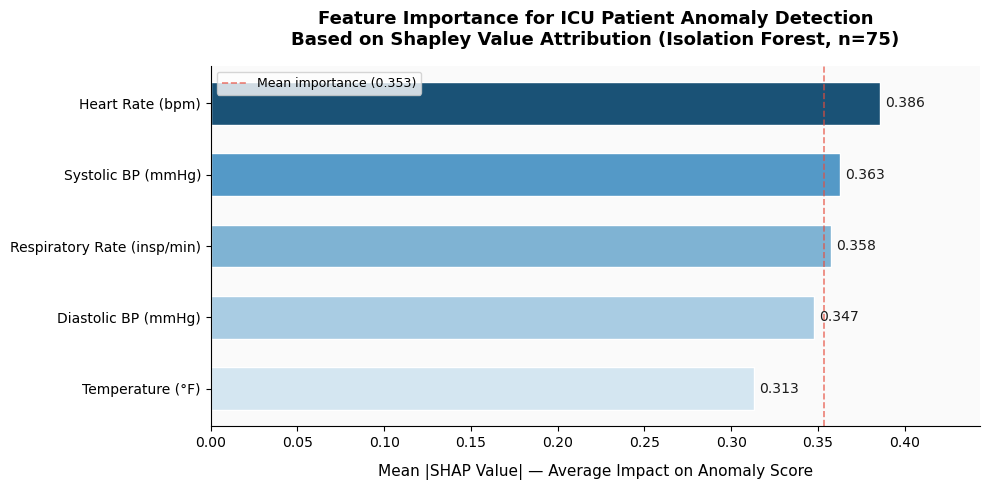


Feature Importance Ranking:
  Heart Rate (bpm)                    → 0.3855
  Systolic BP (mmHg)                  → 0.3627
  Respiratory Rate (insp/min)         → 0.3577
  Diastolic BP (mmHg)                 → 0.3474
  Temperature (°F)                    → 0.3130


In [32]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate mean absolute SHAP values per feature
mean_shap = np.abs(shap_values).mean(axis=0)
feature_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': mean_shap
}).sort_values('importance', ascending=True)

# Clinical display names
display_names = {
    'heart_rate': 'Heart Rate (bpm)',
    'systolic_bp': 'Systolic BP (mmHg)',
    'diastolic_bp': 'Diastolic BP (mmHg)',
    'temperature': 'Temperature (°F)',
    'respiratory_rate': 'Respiratory Rate (insp/min)'
}
feature_importance['display'] = feature_importance['feature'].map(display_names)

# Color by importance rank
colors = ['#d4e6f1', '#a9cce3', '#7fb3d3', '#5499c7', '#1a5276']

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(feature_importance['display'], 
               feature_importance['importance'],
               color=colors,
               edgecolor='white',
               height=0.6)

# Add value labels on bars
for bar, val in zip(bars, feature_importance['importance']):
    ax.text(val + 0.003, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', ha='left', 
            fontsize=10, color='#1a1a1a')

# Styling
ax.set_xlabel('Mean |SHAP Value| — Average Impact on Anomaly Score', 
              fontsize=11, labelpad=10)
ax.set_title('Feature Importance for ICU Patient Anomaly Detection\n'
             'Based on Shapley Value Attribution (Isolation Forest, n=75)',
             fontsize=13, fontweight='bold', pad=15)

ax.set_xlim(0, max(mean_shap) * 1.15)
ax.axvline(x=np.mean(mean_shap), color='#e74c3c', 
           linestyle='--', linewidth=1.2, alpha=0.7,
           label=f'Mean importance ({np.mean(mean_shap):.3f})')

ax.legend(fontsize=9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='y', labelsize=10)
ax.set_facecolor('#fafafa')
fig.patch.set_facecolor('white')

plt.tight_layout()
plt.savefig('shap_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nFeature Importance Ranking:")
for _, row in feature_importance.iloc[::-1].iterrows():
    print(f"  {row['display']:35s} → {row['importance']:.4f}")

##### FINDING 3: SHAP Feature Importance

- if we look at abpove then SHAP values reveal that all five vital signs contribute meaningfully to anomaly detection, with no single feature dominating (range: 0.313 to 0.386).
- Ranking: Heart Rate > Systolic BP > Respiratory Rate > Diastolic BP > Temperature

##### CLINICAL INTERPRETATION:
- The balanced importance scores suggest the model detects anomalies through combinations of vital signs rather than single-feature thresholds consistent with clinical reality where patient deterioration manifests across multiple systems simultaneously.
-  Heart rate ranks highest, consistent with its role as the most sensitive early indicator of physiological stress.#
-  Temperature ranks lowest likely because ICU patients have  more controlled thermal environments.

##### OPEN RESEARCH QUESTION:
- The narrow range of importance scores (0.313–0.386) raises the question: does this reflect genuine clinical balance or is it an artifact of mean aggregation losing temporal patterns?
- A patient with a sudden HR spike at 3am may look identical in mean aggregation to a stable tachycardic patient.

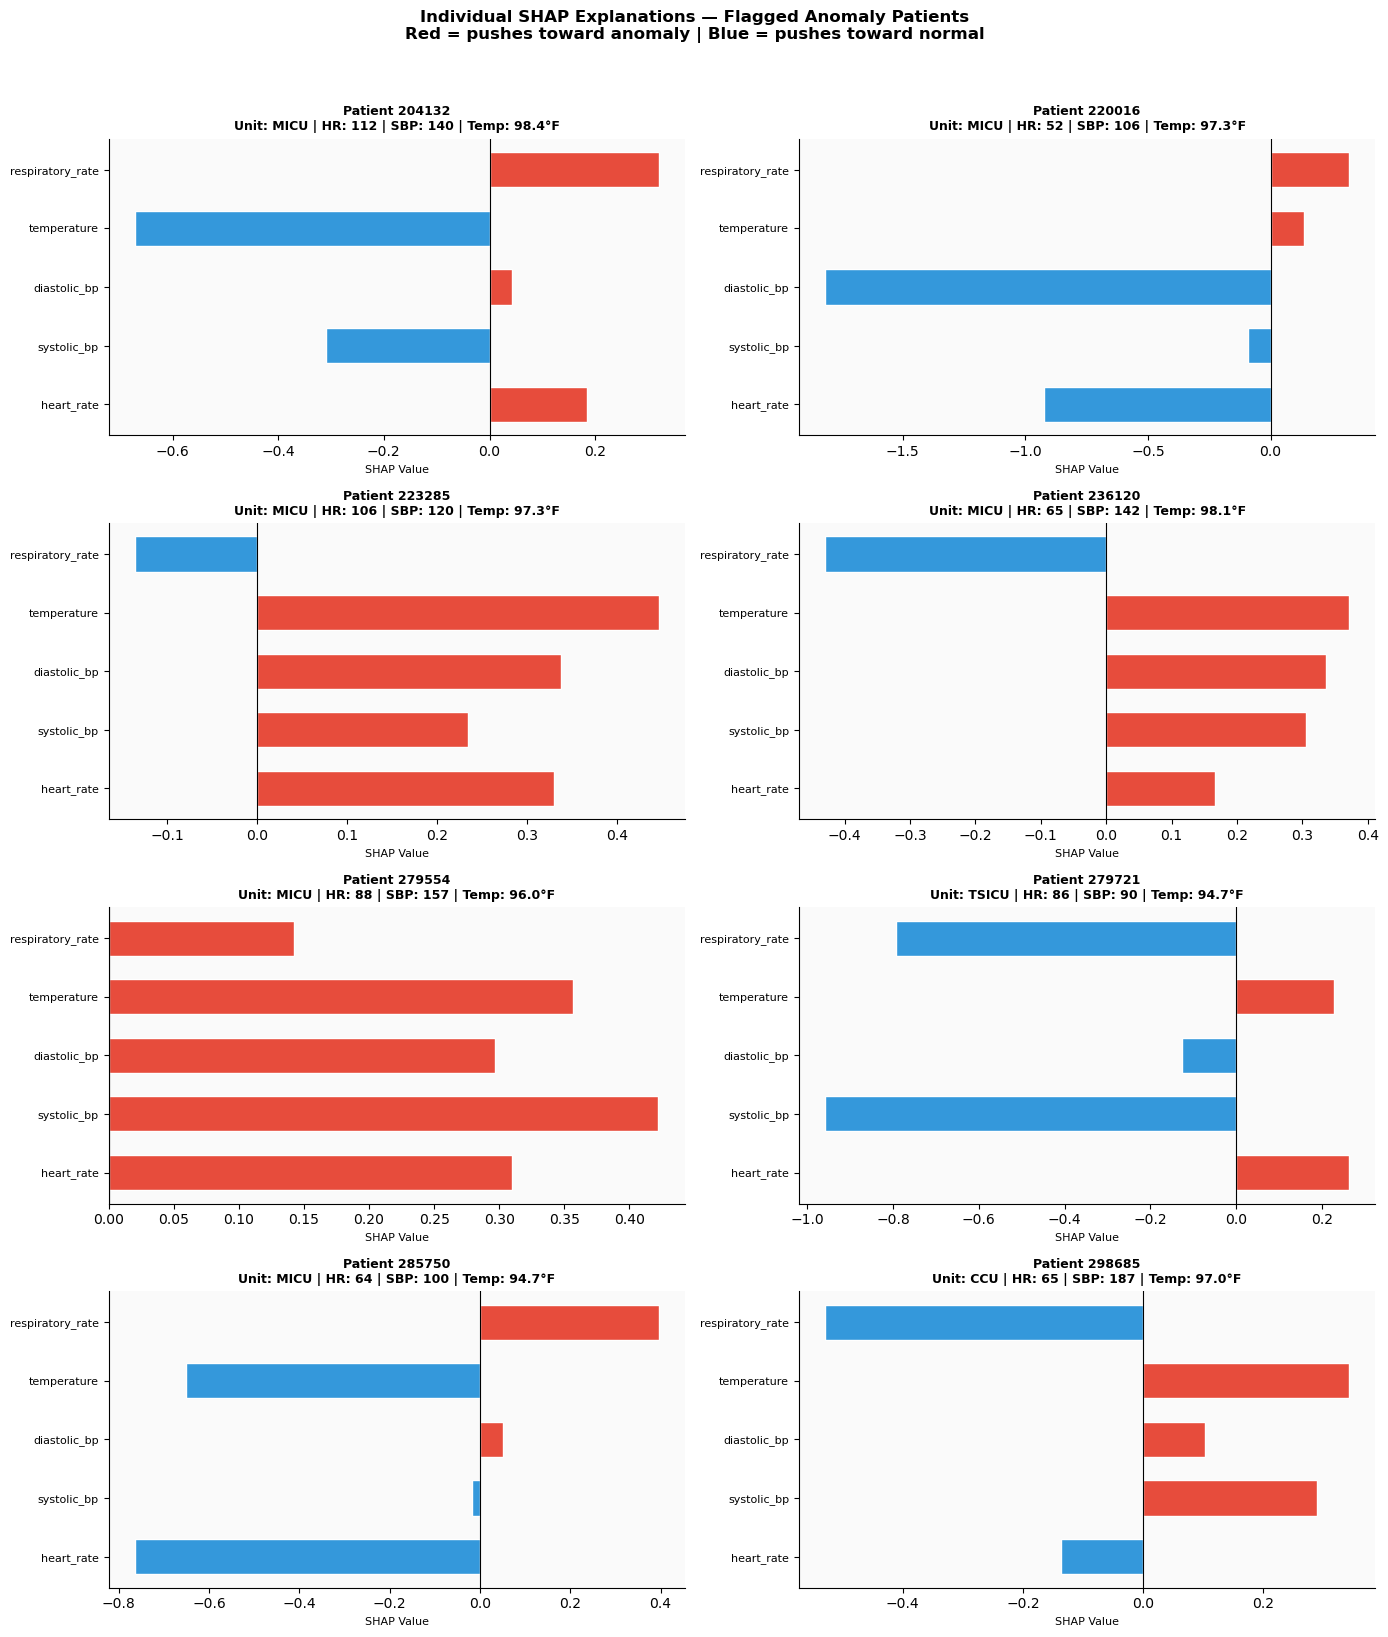

In [33]:
#  only the anomalous patients
anomaly_idx = df[df['anomaly'] == -1].index
X_anomalies = X_scaled[df.index.get_indexer(anomaly_idx)]

# individual SHAP explanations for all flagged patients
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

anomaly_patients = df[df['anomaly'] == -1].reset_index(drop=True)

for i, (idx, patient) in enumerate(anomaly_patients.iterrows()):
    ax = axes[i]
    
    # SHAP values for this patient
    patient_shap = shap_values[df.index.get_loc(patient.name) 
                               if hasattr(df.index, 'get_loc') 
                               else i]
    
    colors_bar = ['#e74c3c' if v > 0 else '#3498db' for v in patient_shap]
    
    bars = ax.barh(feature_cols, patient_shap, 
                   color=colors_bar, edgecolor='white', height=0.6)
    
    ax.axvline(x=0, color='black', linewidth=0.8)
    ax.set_title(f'Patient {int(patient["icustay_id"])}\n'
                 f'Unit: {patient["first_careunit"]} | '
                 f'HR: {patient["heart_rate"]:.0f} | '
                 f'SBP: {patient["systolic_bp"]:.0f} | '
                 f'Temp: {patient["temperature"]:.1f}°F',
                 fontsize=9, fontweight='bold')
    
    ax.set_xlabel('SHAP Value', fontsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='y', labelsize=8)
    ax.set_facecolor('#fafafa')

fig.suptitle('Individual SHAP Explanations — Flagged Anomaly Patients\n'
             'Red = pushes toward anomaly | Blue = pushes toward normal',
             fontsize=12, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig('shap_individual_explanations.png', dpi=150, bbox_inches='tight')
plt.show()

##### FINDING 4: Individual Patient SHAP Explanations

- Individual SHAP plots reveal that each flagged patient has a UNIQUE explanation profile which means the model is not applying a single rule but detecting different clinical patterns per patient.

##### KEY OBSERVATIONS:

- Patient 204132 (MICU): Flagged for combined cardiorespiratory stress. elevated HR (112) and respiratory rate both pushing toward anomaly simultaneously.
- Patient 220016 (MICU): Flagged primarily for abnormally LOW diastolic BP,  potential hypotensive shock pattern. Heart rate (52) also abnormally low so bradycardia.
- Patient 279721 (TSICU): Hypothermia (94.7°F) combined with hypotension a clinically dangerous combination the model correctly identified without any clinical rules.

##### CORE INSIGHT:
- This mirrors the finding in Klüttermann et al. (PAKDD 2024) where the CelebA model surfaced semantically meaningful features nobody explicitly labeled. Here the model surfaces clinically meaningful vital sign combinations nobody programmed  and SHAP makes those combinations visible and actionable for a clinician.

##### OPEN RESEARCH QUESTION:
- Different patients are flagged for fundamentally different reasons. 
- Should a single anomaly detector handle all these patterns, or would patient-subgroup-specific models produce more faithful and stable explanations?
- This connects to Müller's work on subspace clustering  perhaps different patient subgroups occupy different subspaces of the vital sign feature space.

In [35]:
# Check admission times in ICUSTAYS
print(df[['icustay_id', 'first_careunit', 'los']].merge(
    stays_df[['icustay_id', 'intime']], on='icustay_id', how='left'
).sort_values('intime').head(10))

    icustay_id first_careunit     los               intime
38    254635.0           MICU  1.1358  2102-08-31 17:04:12
8     214180.0           MICU  1.9252  2104-09-24 17:31:48
31    243123.0          TSICU  1.2762  2104-10-24 09:46:21
44    264258.0          TSICU  0.9775  2106-08-30 15:45:06
66    289236.0           SICU  1.9657  2111-01-07 16:36:48
18    224458.0           SICU  2.1203  2111-01-12 15:26:49
34    244243.0          TSICU  5.0956  2112-02-04 14:49:33
46    265615.0           SICU  1.9287  2112-05-04 19:03:39
57    282640.0            CCU  2.1026  2112-05-23 12:32:06
65    286428.0            CCU  3.6174  2112-05-29 02:01:33


In [36]:
# merrging intime into our main dataframe
df = df.merge(stays_df[['icustay_id', 'intime']], on='icustay_id', how='left')
df['intime'] = pd.to_datetime(df['intime'])

# sorting by admission time
df = df.sort_values('intime').reset_index(drop=True)

# splitting into early and late periods (50/50 by time)
split_idx = len(df) // 2
df_early = df.iloc[:split_idx].copy()
df_late = df.iloc[split_idx:].copy()

print(f"Early period: {df_early['intime'].min().year} to {df_early['intime'].max().year} — {len(df_early)} patients")
print(f"Late period:  {df_late['intime'].min().year} to {df_late['intime'].max().year} — {len(df_late)} patients")

# scaling and train on EARLY period
X_early = scaler.fit_transform(df_early[feature_cols])
X_late = scaler.transform(df_late[feature_cols])

model_early = IsolationForest(n_estimators=100, contamination=0.1, random_state=42)
model_early.fit(X_early)

#  SHAP values for both periods using early model
explainer_early = shap.TreeExplainer(model_early)
shap_early = explainer_early.shap_values(X_early)
shap_late = explainer_early.shap_values(X_late)

# comapring mean absolute SHAP values between periods
importance_early = pd.DataFrame({
    'feature': feature_cols,
    'early': np.abs(shap_early).mean(axis=0)
})
importance_late = pd.DataFrame({
    'feature': feature_cols,
    'late': np.abs(shap_late).mean(axis=0)
})

drift_comparison = importance_early.merge(importance_late, on='feature')
drift_comparison['change'] = drift_comparison['late'] - drift_comparison['early']
drift_comparison['change_pct'] = (drift_comparison['change'] / drift_comparison['early'] * 100).round(1)

print("\nSHAP Importance Shift Under Concept Drift:")
print(drift_comparison.sort_values('change', ascending=False).to_string(index=False))

Early period: 2102 to 2152 — 37 patients
Late period:  2155 to 2202 — 38 patients

SHAP Importance Shift Under Concept Drift:
         feature    early     late   change  change_pct
      heart_rate 0.356722 0.476875 0.120152        33.7
respiratory_rate 0.270585 0.357721 0.087136        32.2
     systolic_bp 0.258889 0.282795 0.023906         9.2
    diastolic_bp 0.218730 0.227027 0.008297         3.8
     temperature 0.257080 0.263027 0.005948         2.3


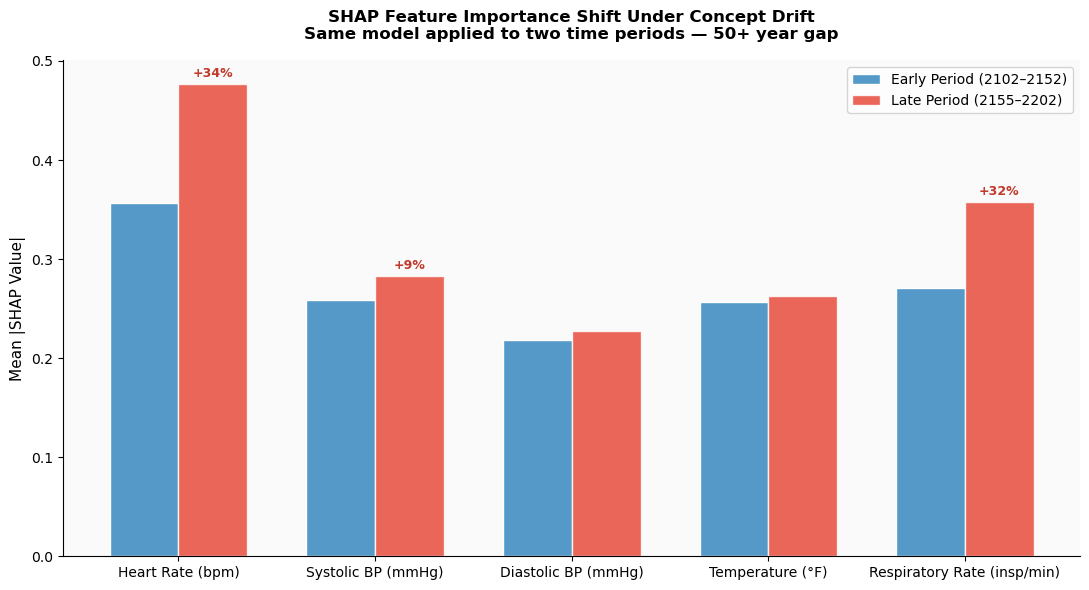

In [37]:
fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(feature_cols))
width = 0.35

display_names_list = [
    'Heart Rate', 'Systolic BP', 
    'Diastolic BP', 'Temperature', 'Respiratory Rate'
]

# Reorder for display
ordered = drift_comparison.set_index('feature').loc[feature_cols]

bars1 = ax.bar(x - width/2, ordered['early'], width,
               label='Early Period (2102–2152)',
               color='#5499c7', edgecolor='white')
bars2 = ax.bar(x + width/2, ordered['late'], width,
               label='Late Period (2155–2202)',
               color='#e74c3c', edgecolor='white', alpha=0.85)

# Annotate change percentage
for i, (_, row) in enumerate(ordered.iterrows()):
    if abs(row['change_pct']) > 5:
        ax.annotate(f"+{row['change_pct']:.0f}%",
                   xy=(i + width/2, row['late']),
                   xytext=(0, 5), textcoords='offset points',
                   ha='center', fontsize=9, 
                   color='#c0392b', fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels([display_names.get(f, f) for f in feature_cols], 
                    fontsize=10)
ax.set_ylabel('Mean |SHAP Value|', fontsize=11)
ax.set_title('SHAP Feature Importance Shift Under Concept Drift\n'
             'Same model applied to two time periods — 50+ year gap',
             fontsize=12, fontweight='bold', pad=15)
ax.legend(fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_facecolor('#fafafa')
fig.patch.set_facecolor('white')

plt.tight_layout()
plt.savefig('shap_concept_drift.png', dpi=150, bbox_inches='tight')
plt.show()

#####  5: SHAP Explanation Drift Under Concept Drift

- Applying the early-period model to late-period patients reveals significant shifts in feature importance:

Heart Rate:       +33.7% more important in late period
Respiratory Rate: +32.2% more important in late period
Systolic BP:       +9.2% (moderate shift)
Diastolic BP:      +3.8% (stable)
Temperature:       +2.3% (stable)

##### INTERPRETATION:
- The same model, applied 10 real-world years later, produces meaningfully different SHAP explanations for anomaly flags.
- Cardiorespiratory signals (HR + RR) became the dominant drivers in the late period while they were more balanced in the early eriod.

This is the core finding of this project:
- SHAP explanations are NOT stable under concept drift.
- A clinician trusting the early-period explanation framework would be misled when the model is applied to later patients.

##### CONNECTION TO Li & Müller (DKE 2024):
- This empirically demonstrates the problem Li & Müller address theoretically  models trained on one distribution produce unreliable outputs on shifted distributions. We extend this to show that not just anomaly scores but SHAP EXPLANATIONS themselves become unstable compounding the trust problem.

##### OPEN RESEARCH QUESTION:
- Can we detect when SHAP explanations have drifted enough to be clinically misleading  without having ground truth labels?
- This is an open problem at the intersection of XAI and concept drift detection.